# Day 1
This Lab Journal describes our way in measuring brownian motion under the microscope and using the quantitative results to find another quantity or verify something else. 

We attended the introduction presentation.

We initialised our github repository for collaboration at <https://github.com/HiperLoop/LAB>.

We looked into the sample-preparation. The liquids we have at our disposal are monodisperse polystyrene microspheres of the sizes of 0.5-2 $\eta\text{m}$ who are collodial suspensed in water and concentrations of 1%, 0.5%, 0.1%, 0.05%, and 0.01%. To prepare a sample, we are pipetting 1-2 drops on a sample holder and cover it with a glas plane. Importantly, we have to mix the solution before we are taking drops out, since the particles would drop within minutes to the ground. Then we transport it back to the microscope.

In this experiment, we are using the Bleeker Microscope with an external light source and the DinoExe CCD Camera on top of the microscope to take videos of samples under the microcope. We started by trying to setup the camera and install all the necessary software. We ran into problems with Dino capture 3.0 so we installed the 2.0 version and that worked for us. We are therefore now able to live-monitor the video of the microscope on our laptops. We have also found out that we can set the saving location for the data (videos and pictures) directly in our directory that is shared via githubg so that we both have access to the files.

We tried our first setup. We had a lot of trouble pointing the light in the right direction to see any image from the microscope. We then found out that the magnification lenses on the microscope do not produce any image. We investigated this with the TA. In the end we decided to switch microscopes as it seemed to be an issue with the lenses.

For the light source, after experimenting with a flexible light source, for the sake of consistency we decided that we will put everything on the holds so that we can focus the light and keep a constant distance between light source and lens. We then tried to focus the light so that the sample lies in the focus point of the other lens in the Bleeker microscope, which proved to be quite difficult. We are using the strongest lens whose attributes are not further quantified.

Image of our first setup.

![Image of our first setup](<Lab Journal/Screenshot 2026-10-30 145737.png>){width=50%}

Eventually, we noticed that using the focus lense did not enhace our image in any way therefore we decided to use the light directly on the mirror of the microscope since that produced sufficient ligting to achieve good results. After that plus switching microscopes we were able to produce our first good images of moving particles.

![alt text](<Lab Journal/A003-20261007_153704.jpg>){width=50%}

We reproduced the results with the different microscope strenghts, but eventually settled on N40 x 0.65 since this seemed to be the best tradeoff between sample size and clearness of movement. We took a first video that we wanted to use to start with trackpy since we wanted to be sure that we can quantify the quality of the videos we were taking. 

We started by using the first frame of the video. The first step is to picturing the image in a grey-scale. This is especially important because that means that the colors that we are seeing in the image and that are clearly recognizable for us, will not be benificial for trackpy at all. We then used the build-in functions of trackpy tp.locate to find all of the particles and plotted the localized particles with the red circles as in the example document (https://soft-matter.github.io/trackpy/dev/tutorial/walkthrough.html). 
Here, one can use two different initial parameters for the localize function, the minimal mass necessary for something to be considered a particle and the assumed feature size. For our first video, we settled on 2000 as the minimum mass since this filtered out potential noise that was seen as a particle before. The feature size worked best for us when we used 19. 

This is clearly not yet fully functional but was good enough for us to see a first result. For future videos we assume that this will have to be refined individually. Due to time constraints, this is where we are ending for the first day. 

**Note** we have been lacking in putting the WIP code into our labjournal. This is why some of them have been added or edited later on so that they also work within the notebook. This is also why the package import is much bigger then immediately needed but so that everything is at one point.

In [1]:
#EDITED LATER: packages we will be using over the course of this project
import os
import typing
import matplotlib as mpl
import matplotlib.pyplot as plt
import pims
import trackpy as tp
from pandas import DataFrame, Series
import numpy as np
import pandas as pd
from scipy.constants import Boltzmann
from scipy.optimize import curve_fit

mpl.rc('figure', figsize=(6, 3.5))
mpl.rc('image', cmap='gray')

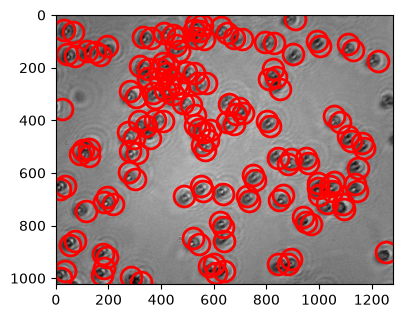

<Axes: >

In [2]:
def gray(image: Series) -> Series:
    '''Make image monochromatic by just taking the green channel in the RGB values.'''
    return image[:, :, 1]

def loadImageAsGrey(image_name: str):
    '''Load an image and keep only the green channel.'''
    frame = pims.open(image_name)[0]   # first (and only) frame, an array of shape (height, width, 3)
    return frame[:, :, 1]
mpl.rc('figure', figsize=(6, 3.5))

image=loadImageAsGrey('Lab Journal\\A003-20261007_153704.jpg')
f = tp.locate(image, 19, invert=True, minmass=2000)
tp.annotate(f, image)

# Day 2

We tried to get the microscope setup working the way we had it last time. After discussion with the TA, we decided that the lack of sharpness in the image above is most likely due to us not using a lens to bundle the light, which is why we tried to bundle our light again with a setup similar to the picture above with a lens and a light source, where we again used the strongest lens to bundle the light as much as possible so that we have a strong light source.
Finding particles this time proved to be significantly more difficult than we initially anticipated. We tried numerus samples, tried to utilize the different magnifications and different light sources but nothing helped anything. Eventually, we found out that both of the microscopes we were using had a problem. The first one had a broken magnification lens, while the second one had a problem in the eye channel. Both of these resulted in us not being able to measure anything. Since it is statistically extremely unlikely that we get our hands on two broken microscopes, we were sure that this was a user problem and spent a solid 2.5 hours on trying everything. Eventually, after receiving a third microscope we were able to get an image within minutes. This image is shown below.

![alt text](<Lab Journal/A006-20261009_122538.jpg>){width=50%}

We have added a function in our code that can slice the videos in the seperate images so that we can use the abovementioned functions for every frame. 
The instructions state that for the video to be good, you have change manually in DinoCapture the video resolution to 640x480 (HS). We forgot to do this for our sample video, which is why the tracking did not work great. After correcting for that, the tracking was still not perfectly seeing the values. However, due to the enourmous time-loss, the troubleshooting had to be postponed to the next session.

In [3]:
VIDEO_PATH: str = './data/Adam Data/Video/'

def loadFramesFromVideo(video_name: str) -> Series:
    '''Load all video frames and convert them to monochrome.'''
    return gray(pims.open(f'{VIDEO_PATH}{video_name}'))

def processFrames(frames: Series, feature_size: int, minmass: int, show_plot: bool = False) -> DataFrame:
    '''Annnotate all frames with detected particles.'''
    tp.quiet()
    processed_frames: DataFrame = tp.batch(list(frames), feature_size, invert=True, minmass=minmass)
    if show_plot: tp.annotate(processed_frames, frames[0])
    return processed_frames


# Day 3

We set up the microscope again, this time it took much less time. 

Our goal for today is to get a setup, eg. code that can work directly with recorded videos, that is capable of analysing data in a usefull manner so that we can think about what we would be capable of researching for our project. Naturally, this is the wrong order in comparision to a normal experiment, but it also seems to be in the nature of how the problem of this experiment is being posed. 

To make sure that we can do that as well, we tried a sample with smaller particles for the first time. We switched from observing the 2 micrometer particles to 500 nanometer particles, while keeping the concentration the same at 0.1%. We tried using the biggest magnification to see the particles but struggled to setup the microscope and lightsource so that we can see the particles. Since we also saw from other groups (and confirmed ourselves later), the magnification is sufficient to track particles of all available sizes so we decided that we will stick to the N40 x65, therefore the second highest magnification available to us. We are planing on keeping that constant for the rest of the experiment so that we can also properly compare the length measurements.

We then took a few first videos to test our tracking on. We realised that since we are using trackpy with a grey-scale, the white dots in the middle of our samples are actually disturbing the measurement, since it is assumed to be background. This is why we tried to alter our image in a way that the particles are slightly more unsharp, but more monochromatic and therefore easier to be tracked. Below, we have used the top format and not the bottom.

![alt text](<Lab Journal/A009-20261014_143252.jpg>){width=50%}

![alt text](<Lab Journal/A010-20261014_143259.jpg>){width=50%}

There are two variables that Trackpy gets from us that are variable and define what is to be tracked, namely the minimum mass and the estimated feature size in pixels. For this, we compared the same image with different parameters and visualized the particles that got detected. For the minmass, we tried to this time take a bit more of a rigourus approach, since our image was much clearer than on day one. We therefore used a mass histogram to look into what might be noise and what are actual particles:

[Text(0.5, 0, 'mass'), Text(0, 0.5, 'count')]

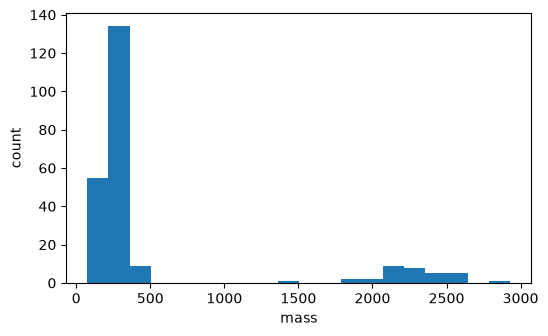

In [4]:
image=loadImageAsGrey('Lab Journal/A009-20261014_143252.jpg')
f = tp.locate(image, 19, invert=True, minmass=0)

fig, ax = plt.subplots()
ax.hist(f['mass'], bins=20)
mpl.rc('figure', figsize=(6, 3.5))

ax.set(xlabel='mass', ylabel='count')

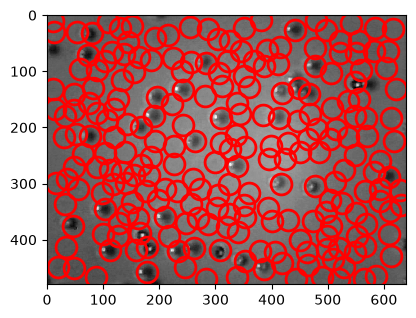

<Axes: >

In [5]:
mpl.rc('figure', figsize=(6, 3.5))

tp.annotate(f, image)

Therefore, we set the minimum mass at 1500 for the 2 micrometer samples on this amplification, which we analysed out of the histrogram. by obsseving at what mass the majority of particles is concentrated. The result is much more clearly only looking at the relevant particles. 

[Text(0.5, 0, 'mass'), Text(0, 0.5, 'count')]

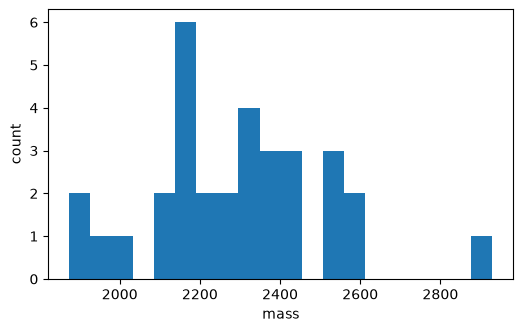

In [6]:
mpl.rc('figure', figsize=(6, 3.5))

f = tp.locate(image, 19, invert=True, minmass=1500)

fig, ax = plt.subplots()
ax.hist(f['mass'], bins=20)

ax.set(xlabel='mass', ylabel='count')

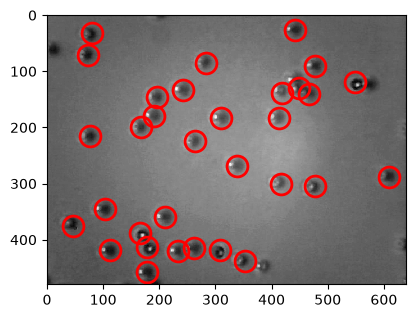

<Axes: >

In [7]:
mpl.rc('figure', figsize=(6, 3.5))

tp.annotate(f, image)


Clearly, there are also some particles that are not being detected. We decided to deal with that in a quite rigoros way by using the trackpy function filter_stubs, where we can define the minimum number of frames that a particle has to be in to contribute towards the trajectories. We set this to be over the course of the whole video, therefore we are only counting particles that are being tracked for in every single frame. This will most likely make our life easier when it comes further data analysis since this means that there is data for every particle at every frame. 

Currently, we are still just taking test measuremetns to get the setup running. As soon as we start to take measurements that we want to use in our final result, we will have to think of a way to store the data in a better way then just taking videos.

However, the first next step was using the micrometer ruler provide to calibrate our micrometer to pixel ration. We measured the length between lines at a distance of 80 micrometers to be 616 pixels with the lines being 16px wide, from which we get the value with uncertainty as $616 \pm 16$ px. The uncertainty hereby is the width of one small line, since we assume that this is what we could be off by not putting the markers exactly in the middle, the milimeter measurement device being off or the whole image being slightly rotated. The mpp calibration is then $\frac{80}{616} = 0.130 \pm 0.003 \eta\text{m/px}$. We get the uncertainty from the relative uncertainty, which is $\frac{16}{616} \approx 0.02597$. The absolute uncertainty is then $\frac{80}{616} \cdot 0.02597 \approx 0.003$. 

![alt text](<Lab Journal/Screenshot 2026-10-30 121942.png>){width=50%}

![alt text](<Lab Journal/Screenshot 2026-10-30 122206.png>){width=50%}

# Day 4
## Plan of Work
We decided that we want to find the viscosity of the samples we are given. We are calculating this by using the Stokes-Einstein-Relation:
$$
D = \frac{k_BT}{6\pi\eta a} 
$$
Here, $T$ is the room temperature which is given by the thermometer and in our case 21°C, $k_B$ and $\pi$ being constants, $\eta$ being the viscosity we are looking for and $a$ the radius of the particles. At this point we also realised that we are given the diameter of the particles and not the radius which has to be considered in the code. 
Therefore, the only unknown is the diffusion constant $D$. Following the instructions, we can get that one based on the average displacement.  

We are hypothisizing that there might be an impact of the particle sizes on the viscosity. To investigate this, the following step-by-step scheme can be applied: 

1. Measurement: Taking videos of the diffusion of samples with different particle size
2. Data analysis of one sample: 
    * Analysing the trajectories of the particles and storing them as an array
    * Calculating the mean displacement of all of the particles per timestep 
    * We are then plotting the mean displacement against the time. Due to the relation $D=\frac{\text{d}<R^2>}{\text{dt}}=\frac{<R^2>}{\Delta t}$, if we do a linear fit through that, the slope will be the diffusion constant
3. Measuring the diffusion constants for different particle sizes and use the Stokes–Einstein–Sutherland relation to calculate the viscosity for all of the measured samples. 
4. Take the average for all measurements taken in the same data. The results should be similar to each other.
5. Plot the resulting viscocity against the radius and see the relation between 

A very dirty research hints that the impact should be of the order of 0.1mPa/s. This will be investigated further soon.

#### Uncertainties
We are currently thinking about the following uncertainties: 

1. Uncertainty in the transformation between pixels and SE units due to the ruler 
2. Drift / Turbulances in the sample --> corrected by tp.compute_drift and tp.substract_drift for symetries between the particles
2. Uncertainty in the tracking of the particles --> trackpy itself is having a subpixel accuracy but only if it clearly identifies the particles. Especially when there is noise or white dots in the middle, it is hard to account for that. 
2. Uncertainty due to particles bumping into each other --> tried to be corrected by reducing the concentration until it does not happen again
3. The Randomness of the motion --> should be statistically irrelevant for the amount of particles we are measuring every step
4. Uncertainty in the time per frame 
5. Uncertainty in the lab value for the particle size 
6. Uncertainty in room temperature

These are all of the experimental uncertainties we can think of. These will give us total uncertainties for  $<R^2>$, $\Delta t$, and $a$. The first two will be passed on with the fit for $D$ and then together with the average will create an uncertainty for $\eta$. The uncertainty in $a$ will be an uncertainty on the x-axis which is only relevant when we can quantify the impact of the particle size on the viscocity.

We now continued to work on our code. First, we worked on properly finding the tracetories of all of the particles. As a first sanity check, we just plotted the trajectories so that we can see that it works and spot any clearly visible odd aspects. This is just a sanity check example, we went forward refining this much more.
**Note** The following is a code that is using the functions we defined but was changed to work in markdown. We mainly used the code in the old_main so please use that as a proper reference of what we have been using it for. We are still trying to get used to how to implement markdown in the workflow so this is everything but optimal.

Frames: 60 | frame shape: (480, 640)
Located features: 4515


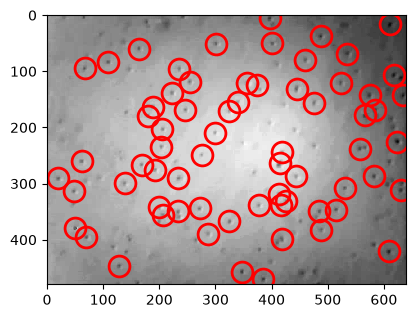

Particles before/after filter_stubs: 365 / 179


<Figure size 600x350 with 0 Axes>

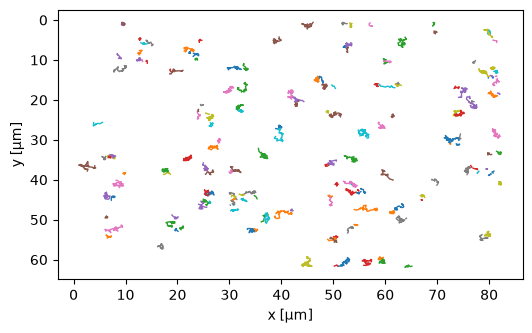

In [8]:
VIDEO_PATH = 'Lab Journal'
VIDEO_FILE = 'A011-20261016_122707.wmv'   
FEATURE_SIZE = 9
MINMASS = 200
FRAME_LIMIT = 60
CALIBRATION_FACTOR = 0.13                   
REMOVE_DRIFT = True
# ------------------------------
mpl.rc('figure', figsize=(6, 3.5))


tp.quiet()

@pims.pipeline
def gray(frame):
    '''Keep only the green channel of an RGB frame.'''
    return frame[:, :, 1] if frame.ndim == 3 else frame

def loadFramesFromVideo(video_name: str):
    '''Load all video frames and keep only the green channel.'''
    path = os.path.join(VIDEO_PATH, video_name)
    if not os.path.exists(path):
        raise FileNotFoundError(f'Video not found: {os.path.abspath(path)}')
    return gray(pims.PyAVReaderIndexed(path))

def processFrames(frames, feature_size: int, minmass: int) -> DataFrame:
    '''Locate the particles in all frames.'''
    return tp.batch(list(frames), feature_size, invert=True, minmass=minmass)

def calculateTrajectories(located: DataFrame, min_frames: int) -> DataFrame:
    '''Link particle positions into trajectories and remove short and static ones.'''
    trajectories = tp.link(located, 5, memory=3)
    long_trajectories = tp.filter_stubs(trajectories, min_frames)
    print('Particles before/after filter_stubs:',
          trajectories['particle'].nunique(), '/', long_trajectories['particle'].nunique())

    def has_moved(group: DataFrame) -> bool:
        dx = group['x'].iloc[-1] - group['x'].iloc[0]
        dy = group['y'].iloc[-1] - group['y'].iloc[0]
        return (dx**2 + dy**2)**0.5 > 0.01

    return long_trajectories.groupby('particle').filter(has_moved)

# --- Run ---
frames = loadFramesFromVideo(VIDEO_FILE)[:FRAME_LIMIT]
n_frames = len(frames)
print('Frames:', n_frames, '| frame shape:', frames[0].shape)

located = processFrames(frames, FEATURE_SIZE, MINMASS)
print('Located features:', len(located))
if located.empty:
    raise ValueError('No particles found: check FEATURE_SIZE, MINMASS and invert=True.')

plt.figure()
tp.annotate(located[located['frame'] == 0], frames[0])
plt.show()
trajectories = calculateTrajectories(located, n_frames // 8)
if trajectories.empty:
    raise ValueError('No trajectories left after filtering: lower MINMASS or the minimum frame count.')
if REMOVE_DRIFT:
    drift = tp.compute_drift(trajectories)
    trajectories = tp.subtract_drift(trajectories.copy(), drift)

plt.figure()
traj_um = trajectories.copy()
traj_um[['x', 'y']] = traj_um[['x', 'y']] * CALIBRATION_FACTOR   # pixels -> µm

fig, ax = plt.subplots(figsize=(6, 3.5))
tp.plot_traj(traj_um, ax=ax)          
ax.set_xlabel('x [µm]')
ax.set_ylabel('y [µm]')
plt.show()

We started taking samples and were slightly disrupted in that since we had to re-setup our light source. We were once again going with the strongest lense available to us binding the lights so that the sample is in the focus. Nevertheless, our TrackPy showed to be quite good at tracking the big particles which we could verify by checking whether they got tracked for every single frame.

We tried the same measuring method for very small particles. We realised that for high concentration with the current settings we were not able to track them consistently since per measurement with about 35 particles, there were only 1 or 2 that survived the whole measurement period. We were using a few methods to try to refine our image further, such as increasing the contrast artificially within dinocapture itself and changing how much our light is being focussed however decided that it is better if all measurements are taken in one session with the exact same setup, which is why we postponed that to the next session. We also questioned in how far the particles surviving the whole period is really necessary 

# Day 5

We started now by implementing the calculation of the mean square displacement out of the trajectories that we showed above. For this, please reference old_main where we have used the build in function trackpy.emsd to measure the squared mean displacement. We set the lagtime over the course of the whole measurement period. We then plot the squared mean displacement for every timeframe, where we then use a scipy fit through forced through zero and the resulting slope giving us the Diffusion coefficient. We are then using this to calculate the viscosity with the rest given. Currently we are not implementing any uncertainties in that to just get a feeling for now.

Today, our main goal is to take all the samples in one go so that they are comparable when it comes to lighting setup. 
We started with the biggest particles. With today's light setup, we are seeing the particles much more only as black dots, which is better for the trackpy recognition (even though it looks less pretty).

By running our preliminary program over that, we could verify that trackpy tracks all of the particles quite well. However, we realised that our field of depth is still a bit too large, since we cannot see all of the particles super sharp at the same time. We noticed that the particles that are sharper have a higher mass, so we put the cutoff for the mass in the middle of all of the particles that we are measuring. While this does give us less particles, it gives us only the clearest particles, which is what we are aiming for. After a while however we realised that the particles are changing their mass sometimes between frames, so that we had not a lot of particles who sometimes where tracked and sometimes not which is a problem for the average displacement. Furthermore, they are then not surviving for all of the frames, which is why we are not including them in the final measurement.  

After looking also at the second sample, we realised that all of our graphs had disturbances at the very end. After discussing, we realised that this might be because of the lag time that we set within trackpy movement of the table created by us turning of the measurement. If it is being set over the whole time, it takes the average over all frames that come after the point in time. Therefore, we were taking the average about the de-facto same thing for everything **but** the last few frames. We therefore set the lagtime only to 1/4 of the frames and cut off the last bit of all of the videos so that the end would still take sufficient amounts of frames.

We made a plot of our calcualted viscosities for particles of radii $r = 1.5, 1, 0.75\eta m$ and got

![alt text](<Lab Journal/Screenshot 2026-10-30 122302.png>){width=50%}

Including also particles of radius $r = 2\eta m$ we get

![alt text](<Lab Journal/Screenshot 2026-10-30 122354.png>){width=50%}

These results imply that there is a somewhat linear relationship between the viscosity and the radius. Even though this was going against our physical intuition, we decidid that we will try to investigate this further. We use hereby the fact that a viscosity of 2 mPa/s is about the one of milk and 5 is more or less scrambled eggs. Therefore, everything around 1 seemed reasonable for us but 2 also seemed okay if we assume the particles might have an impact, which we cannot judge yet. We decided that we want to investigate this more thoroughly at a later point but for now focus on taking more measurements. 

# Day 6

Today we would like to take our final measurements so that we can focus on data analysis, theory and writing the article throughout next week. We took a few additional measurements and got the following results, where the line is a linear relationship between viscosity and radius. 

![alt text](<Lab Journal/Screenshot 2026-10-30 122451.png>){width=50%}

This is even more devaluating the theory that there might be a linear relationship and it seems more like there is an inherent randomness within our samples. We realised that with the new lightsetup, the particles are not greatly tracked. This made us suspicios so we started creating annotated videos, where the particles are circled in every frame, so that we can actually see what trackpy is doing for every frame. The results of this were a bit frustrating because we realised that we severly overestimated the quality of tracking that trackpy was able to do with our data and our values. Instead, we realised that we will have to individually taylor the minmass and feature size for every video by looking through the frames and even then, there are still jumps and sometimes the same particle being seen as two. We are struggeling to understand in how far this might impact the square displacement, especially if the particles are not tracked for a long enough time for 1/4 of the total frames as a lagtime being sufficient. We therefore decided to take one last batch of samples. Hereby, we also filtered out all videos where we noticed some kind of disturbance such as someone hitting the table, even though that should be filtered out by the drift correction we implemented.

In total, we took 82 videos most of them between 3 and 8 seconds. After filtering them out, we had 25 left, for 4 different diameters 2, 1.5, 1 and 0.75 micrometers diameter for the particles. Since we realised that now our program takes a long time to actually effectively work through it every time and we have to many videos to wait for this every time, we decided to restructure our code. For this, we now created a second python program that is doing just the tracking and saves the tracked particle data as a csv file. This file can then be read by the new main file to actually work through the data. This way, we were able to store the data for all of the videos as CSVs so that the consequential data analysis would be much faster. In this process, we hardcoded in our tracking.py file which minmass and feature size gave the best tracking results for this specific values. The chosen values can be found in tracking.py per video. We also included metadata in our CSVs so that working through the data would become easier.´

Coding this and also debugging this for all of the videos took quite a bit of time, which is why we are postponing the final data analysis to next week. All of the videos and their corresponding data can be found in the table below:

In [9]:
import glob
import io
import os
import re

import numpy as np
import pandas as pd
import trackpy as tp
from IPython.display import display
from scipy.constants import Boltzmann

# --- Settings: change these ---
CSV_DIR = 'Lab Journal\\csv_data'            # folder with your trajectory CSVs
COMPUTE_D = True                # also fit D and the viscosity for every video
REMOVE_DRIFT = False            # True only if the CSVs were saved BEFORE drift correction
REPEAT_THRESHOLD_PX = 0.05      # a step smaller than this counts as a repeated frame
# ------------------------------

def readTrajectoryCSV(path: str):
    '''Split one CSV into video name, metadata row and trajectory table.'''
    with open(path, encoding='utf-8') as f:
        lines = f.read().splitlines()

    comments = [l for l in lines if l.startswith('#')]
    data = [l for l in lines if l.strip() and not l.startswith('#')]

    video = next(l for l in comments if 'video:' in l).split('video:')[1].strip().rstrip('.')
    meta = pd.read_csv(io.StringIO('\n'.join(data[:2])), skipinitialspace=True)
    meta.columns = meta.columns.str.strip()
    traj = pd.read_csv(io.StringIO('\n'.join(data[2:])))
    return video, meta.iloc[0].to_dict(), traj

def repeatedFrameShare(traj: pd.DataFrame, threshold_px: float) -> float:
    '''Share of frame transitions in which the particles hardly moved at all.'''
    t = traj.sort_values(['particle', 'frame']).copy()
    g = t.groupby('particle')
    t['gap'] = g['frame'].diff()
    t['step'] = np.hypot(g['x'].diff(), g['y'].diff())
    t = t[t['gap'] == 1]
    if t.empty:
        return np.nan
    return float((t.groupby('frame')['step'].median() < threshold_px).mean())

def fitDiffusion(traj: pd.DataFrame, mpp: float, fps: float, n_frames: int) -> float:
    '''D in m^2/s from the slope of the ensemble MSD (fit through the origin, 2D: MSD = 4 D tau).'''
    emsd = tp.emsd(traj, mpp, fps, max_lagtime=max(n_frames // 4, 2))
    tau = emsd.index.to_numpy()
    msd = emsd.to_numpy() * 1e-12                 # um^2 -> m^2
    slope = np.sum(tau * msd) / np.sum(tau**2)    # least squares through the origin
    return slope / 4

files = sorted(glob.glob(os.path.join(CSV_DIR, '*.csv')))
if not files:
    raise FileNotFoundError(f'No CSV files in {os.path.abspath(CSV_DIR)}')

rows = []
for path in files:
    video, meta, traj = readTrajectoryCSV(path)
    n_frames = int(meta['frames'])
    stamp = re.search(r'(\d{8})_(\d{6})', video)

    row = {
        'file': os.path.basename(path),
        'id': video.split(' - ')[0],
        'video': video,
        'date': pd.to_datetime(stamp.group(1), format='%Y%m%d').date() if stamp else None,
        'diameter_um': meta['particle_diameter'],
        'diameter_unc_%': meta['diameter_uncertainty'] * 100,   # stored as a fraction
        'T_C': round(meta['temperature'] - 273.15, 2),
        'fps': meta['fps'],
        'mpp': meta['mmp'],
        'mpp_unc': meta['mmp_u'],
        'feature_size': int(meta['feature_size']),
        'minmass': int(meta['minmass']),
        'min_frames': int(meta['visible_frames']),
        'n_frames': n_frames,
        'n_particles': traj['particle'].nunique() if not traj.empty else 0,
        'mean_track_frames': traj.groupby('particle').size().mean() if not traj.empty else np.nan,
        'repeated_frame_share': repeatedFrameShare(traj, REPEAT_THRESHOLD_PX) if not traj.empty else np.nan,
    }

    if COMPUTE_D and not traj.empty:
        t = tp.subtract_drift(traj.copy(), tp.compute_drift(traj)) if REMOVE_DRIFT else traj
        try:
            D = fitDiffusion(t, meta['mmp'], meta['fps'], n_frames)
            radius = meta['particle_diameter'] / 2 * 1e-6
            row['D_um2_per_s'] = D * 1e12
            row['viscosity_mPas'] = Boltzmann * meta['temperature'] / (6 * np.pi * D * radius) * 1e3
        except Exception as e:
            print(f'{video}: D fit failed ({e})')

    rows.append(row)

table = pd.DataFrame(rows).sort_values(['diameter_um', 'date', 'id']).reset_index(drop=True)
table = table.round(3)
table.to_csv('measurement_overview.csv', index=False)      # full table, all columns

compact = ['id', 'date', 'diameter_um', 'T_C', 'feature_size', 'minmass', 'n_particles',
           'mean_track_frames', 'repeated_frame_share', 'D_um2_per_s', 'viscosity_mPas']
display(table[[c for c in compact if c in table.columns]])

,id,date,diameter_um,T_C,feature_size,minmass,n_particles,mean_track_frames,repeated_frame_share,D_um2_per_s,viscosity_mPas
0,A006,2026-10-21,0.75,21.0,17,550,9,40.889,0.102,0.198,2.897
1,A032,2026-10-21,0.75,21.0,17,1000,5,47.400,0.542,0.213,2.692
2,A072,2026-10-23,0.75,20.9,9,500,6,32.000,0.576,0.236,2.435
3,A073,2026-10-23,0.75,20.9,9,500,9,15.889,0.667,0.209,2.750
4,A076,2026-10-23,0.75,20.9,9,500,10,12.700,0.646,0.249,2.304
5,A080,2026-10-23,0.75,20.9,9,500,8,24.125,0.441,0.194,2.955
6,A003,2026-10-21,1.00,21.0,17,600,3,60.000,0.119,0.126,3.421
7,A042,2026-10-23,1.00,21.0,17,2000,5,79.200,0.519,0.222,1.943
8,A064,2026-10-23,1.00,20.9,17,1500,6,25.833,0.571,0.213,2.026
9,A065,2026-10-23,1.00,20.9,17,1500,5,27.400,0.592,0.231,1.865


# Day 7

Today we do our final data analysis including the uncertainty propagation, and start writing the article. We started by running the viscossity calculation for all of our data. This then gave us the following plot below:

![alt text](<Lab Journal/Screenshot 2026-10-30 122537.png>){width=50%}

For the uncertainty propagation we started by aggregating the uncertainties of quantities for which we were able to determine the uncertainty. These were: the particle diameter, sample temperature, Diffusion coefficient.

For the particle diameter, we were given the relative uncertainty from the sample preperation as well as the measured values for the particle dimeters as

$0.51, 2\%$

$0.746, 3\%$

$1.06, 1\%$

$1.54, 4\%$

$2.06, 2\%$

For the temperature measurements we used a room thermometer with the smallest unit of $0.1^\circ C$, which we also took as our uncertainty.

For the diffusion coefficient we get the uncertainty from the linear fit of mean squared displacement over time.

In our viscosity calculation we use the formula

$\eta = \frac{k_BT}{6\pi Dr},$

where $k_B$ is the Boltzmann constant, $T$ is the thermodynamic temperature, $D$ is the diffucion coefficient, $r$ is the particle radius. To propagate the uncertainties, we calcualte the relative uncertainties also for the temperature and diffucion coefficient. We then use the quadrature to combine the relative uncertainties as

$\frac{\Delta\eta}{\eta} = \sqrt{\left(\frac{\Delta T}{T}\right)^2 + \left(\frac{\Delta D}{D}\right)^2 + \left(\frac{\Delta r}{r}\right)^2}$,

and we get the absolute viscosity uncertainty as

$\Delta\eta = \eta\sqrt{\left(\frac{\Delta T}{T}\right)^2 + \left(\frac{\Delta D}{D}\right)^2 + \left(\frac{\Delta r}{r}\right)^2}$

We are finding the diffusion constant by finding the slope of a fit through the squared mean displacement and using the build in scipy functions to return an uncertainty. Nevertheless, for this we would need the uncertainties for every single value of the squared mean displacement. The main uncertainty in the squared mean displacement would be due to errors in the tracking and eventually also due to errors in the lag frames, however we could not come up with a way to quantify that. Intuitively, we assume that this will give a systematic error for to little motion and therefore higher viscosity, since trackpy is propably more likely to not see something than to halucinate something. What we can quantify is the uncertainty due to the pixel transferral and we are assuming the trackpy inaccuricy to be 1/16 of the particle size as a relative uncertainty. The result can be seen in the following picture: 


We can now take an average for all 4 of the radii and pass on the uncertainties, which gives the following datapoints where we have also already did a horizontal fit with the uncertainties, since it becomes evident that the uncertainties (calculated and not-calculated) are to big to find a reasonable value for a relationship between the radius and the viscosity: 

![alt text](<Lab Journal/D_fit.png>){width=50%}

![alt text](<Lab Journal/non_averaged.png>){width=50%}

![alt text](<Lab Journal/averaged.png>){width=50%}

We can see that the value for the biggest particles seems quite reasonable (around 1), while the other three seem to be all systematically overstated. This is most likely due to the fact that the tracking of the smaller particles is much hareder then for the bigger ones. 

We will now spend the rest of our time polishing this lab journal and writing the article.

**Notable exception** :
We have found this pretty way to have a build in export for our own notebook, which enables us to hand in this lab journal as a latex pdf. We still think that it is more practical to look at it directly in jupyter notebook but having this option is also nice. 

In [11]:
#uncomment for first usage
#pip install nbformat nbconvert

import nbformat
from nbconvert import PDFExporter

TITLE = "Lab Journal Brownian Motion"
AUTHORS = ["Adam Zich (0074187)", "Bela Brunner (8002193)"]
# ---------------------

with open('lab_journal.ipynb', 'r', encoding='utf-8') as f:
    notebook_content = nbformat.read(f, as_version=4)

# nbconvert's LaTeX template reads the title and authors from the notebook metadata
notebook_content.metadata["title"] = TITLE
notebook_content.metadata["authors"] = [{"name": name} for name in AUTHORS]

pdf_exporter = PDFExporter()
body, resources = pdf_exporter.from_notebook_node(notebook_content)

with open('lab_journal.pdf', 'wb') as f:
    f.write(body)